# Modelo de Stuart–Landau de cerebro completo — Fases 0 y 1

**Modelo** (Deco et al. 2017), una ecuación por región $j=1,\dots,N$:
$$\dot z_j = (a_j + i\omega_j)\,z_j - |z_j|^2 z_j + G\sum_k C_{jk}(z_k - z_j) + \beta\,\eta_j(t),$$
con $\mathrm{Re}(z_j)$ comparado con el BOLD filtrado (0.008–0.08 Hz) de la región $j$.

**Linealización.** Para $a<0$ el origen es estable y $u=[x;y]$ obedece un Ornstein–Uhlenbeck $\dot u = A u + \beta\,\xi$, con
$$J = \mathrm{diag}(a+i\omega) - G L,\qquad A = \begin{pmatrix}\mathrm{Re}J & -\mathrm{Im}J\\ \mathrm{Im}J & \mathrm{Re}J\end{pmatrix}.$$
- Covarianza sin filtrar: Lyapunov $A\Sigma + \Sigma A^\top + \beta^2 I = 0$.
- Covarianza **filtrada** (como se procesa el BOLD): $\Sigma_H = 2\,\mathrm{Re}\int_0^{f_N} |H(f)|^4\,(2\pi i f - A)^{-1}\beta^2(2\pi i f - A)^{-H}\,df$, calculada vía la descomposición espectral de $A$.
- Distancia a la criticalidad: $\delta = -\max\mathrm{Re}\,\lambda(J)$; el tiempo de relajación más lento es $1/\delta$.

Código: `src/hopf.py` (modelo), `src/metrics.py` (FC, FCD, metaestabilidad), `src/data.py` (datos HCP).

In [1]:
import sys, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import hopf, data, metrics as M
from IPython.display import Image, display
%matplotlib inline

## Fase 0 — ¿Coincide la teoría lineal con la simulación no lineal?

Red aleatoria de 20 nodos, $G=1$, $\beta=0.02$, 12 000 s simulados por punto (`src/check_linear.py`).

**Resultado.**
- El **patrón de FC** lineal coincide con el simulado con $r>0.98$ en todo el rango, incluso muy cerca de la bifurcación ($a=-0.001$, $r=0.996$).
- Las **amplitudes** (varianzas) coinciden dentro del error estadístico (2–5 %) mientras $\langle|z|^2\rangle/|a| \lesssim 0.2$. Más cerca de $a=0$ la no linealidad cúbica satura la amplitud y la teoría lineal sobreestima la varianza (23–30 % de error).
- Interpretación: **la estructura de correlaciones la dicta la red (el operador lineal); la no linealidad solo controla amplitudes.** Esto justifica ajustar FC con la fórmula analítica y reservar la simulación para cantidades dinámicas (FCD, metaestabilidad).

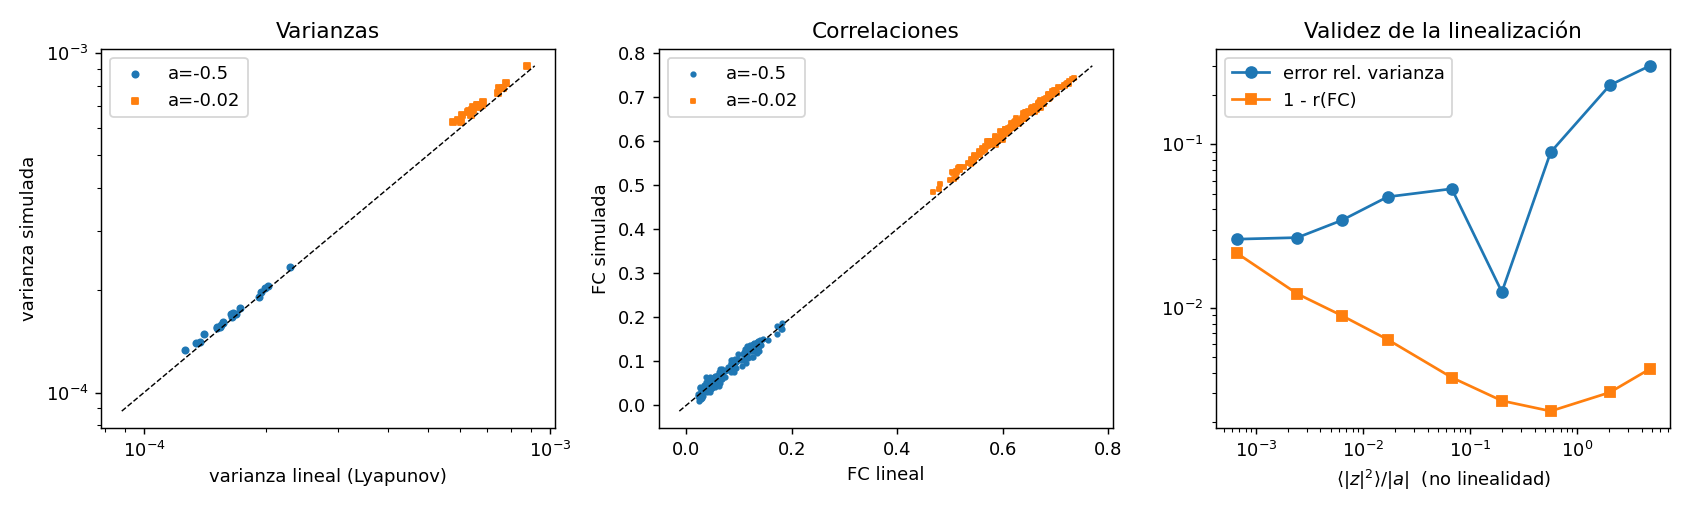

In [2]:
display(Image(str(ROOT / 'figures' / 'fase0_lineal_vs_simulacion.png')))

## Fase 1 — Datos HCP

7 sujetos del HCP (subconjunto distribuido con *neurolib*), parcelación AAL2 de 94 regiones, 1200 volúmenes, TR = 0.72 s. SC = conteo de estreamlines (tractografía probabilística), simetrizado y normalizado a máximo 0.2.

In [3]:
g = data.load_group()
C, TR = g['C'], g['TR']
BAND = (0.008, 0.08)
filt = [M.filter_ts(ts, TR, BAND) for ts in g['ts']]
FC_emp = np.tanh(np.mean([np.arctanh(np.clip(M.fc(x), -0.999999, 0.999999)) for x in filt], axis=0))
freqs = np.mean([M.peak_frequencies(ts, TR, BAND) for ts in g['ts']], axis=0)
omega = 2*np.pi*freqs
print(f"N = {C.shape[0]}, FC media empírica = {M.triu(FC_emp).mean():.3f}")
print(f"frecuencias pico: {freqs.min():.3f}–{freqs.max():.3f} Hz")

N = 94, FC media empírica = 0.373
frecuencias pico: 0.018–0.030 Hz


### Barrido analítico en $(a, G)$
Cada punto toma ~20 ms (sin simular), así que 366 puntos tardan segundos. Este es el ingrediente que hará posible el ajuste individual.

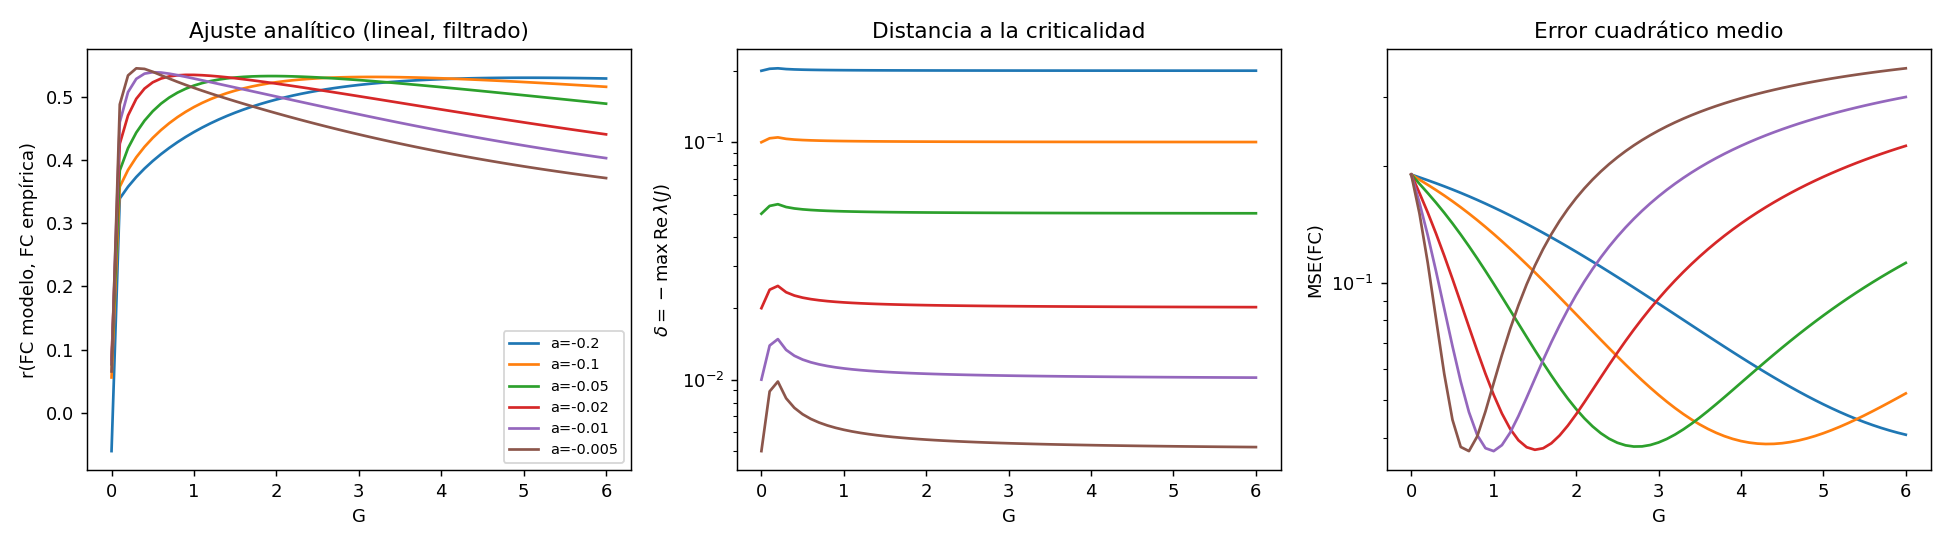

mejor ajuste analítico: a = -0.005, G = 0.30, r = 0.545


In [4]:
res = np.load(ROOT / 'results' / 'fase1_group_fit.npz')
display(Image(str(ROOT / 'figures' / 'fase1_barrido_analitico.png')))
R = res['R']; ib, jb = np.unravel_index(np.nanargmax(R), R.shape)
print(f"mejor ajuste analítico: a = {res['a_grid'][ib]}, G = {res['G_grid'][jb]:.2f}, r = {R[ib, jb]:.3f}")

### Barrido no lineal en $G$ (a = −0.005)
Por cada $G$: 7 simulaciones de la misma duración que los datos, comparadas con FC (patrón y nivel medio), FCD (distancia KS) y metaestabilidad (desviación estándar del parámetro de orden de Kuramoto).

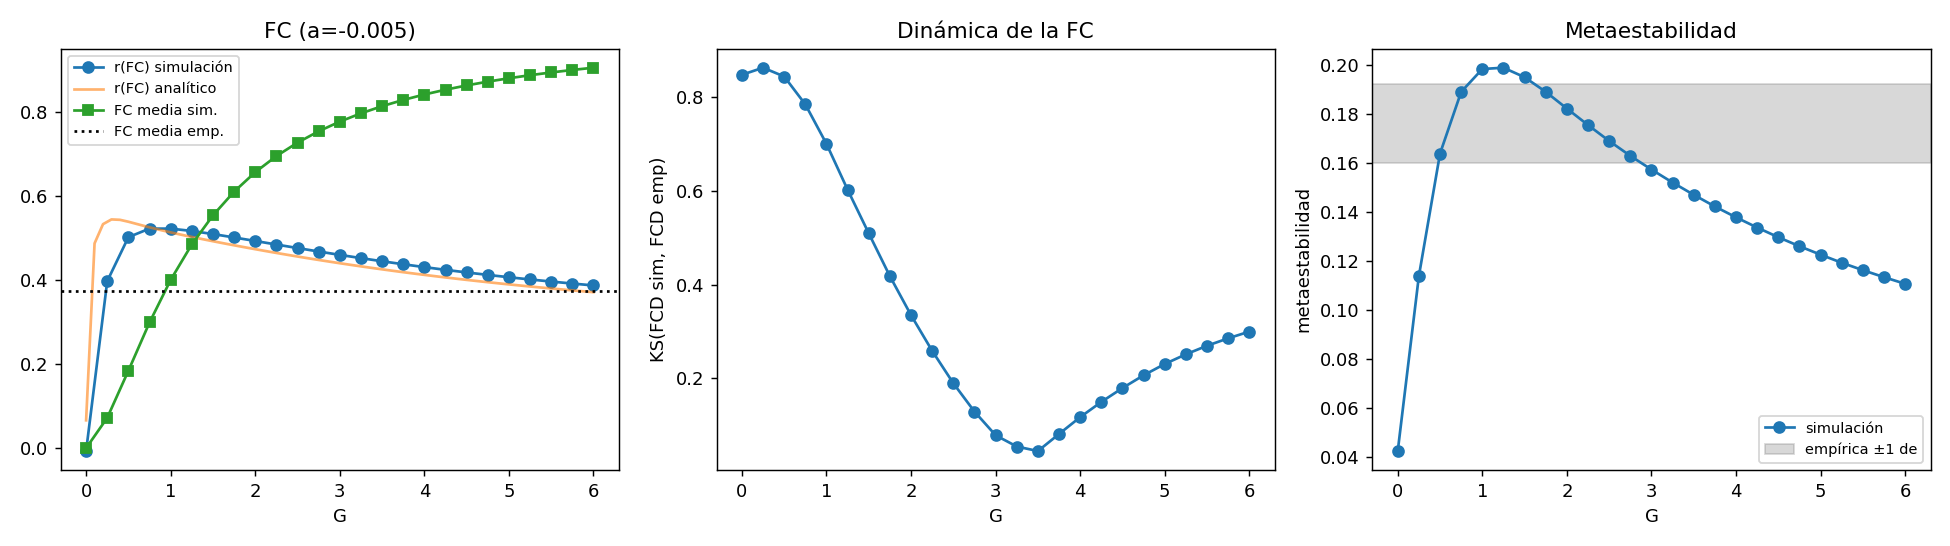

G=0.50  r(FC)=0.503  FC media=0.184  KS(FCD)=0.845  metaest.=0.164
G=0.75  r(FC)=0.523  FC media=0.299  KS(FCD)=0.785  metaest.=0.189
G=1.00  r(FC)=0.523  FC media=0.401  KS(FCD)=0.701  metaest.=0.198
G=1.25  r(FC)=0.517  FC media=0.485  KS(FCD)=0.603  metaest.=0.199
G=2.00  r(FC)=0.493  FC media=0.658  KS(FCD)=0.334  metaest.=0.182
G=3.50  r(FC)=0.445  FC media=0.815  KS(FCD)=0.044  metaest.=0.147
empírico: FC media=0.373, metaest.=0.176±0.016


In [5]:
display(Image(str(ROOT / 'figures' / 'fase1_barrido_no_lineal.png')))
for G, r, mf, k, m in zip(res['G_sim'], res['sim_r'], res['sim_meanfc'], res['sim_ks'], res['sim_meta']):
    if G in (0.5, 0.75, 1.0, 1.25, 2.0, 3.5):
        print(f"G={G:4.2f}  r(FC)={r:.3f}  FC media={mf:.3f}  KS(FCD)={k:.3f}  metaest.={m:.3f}")
print(f"empírico: FC media={M.triu(res['FC_emp']).mean():.3f}, metaest.={res['meta_emp'].mean():.3f}±{res['meta_emp'].std():.3f}")

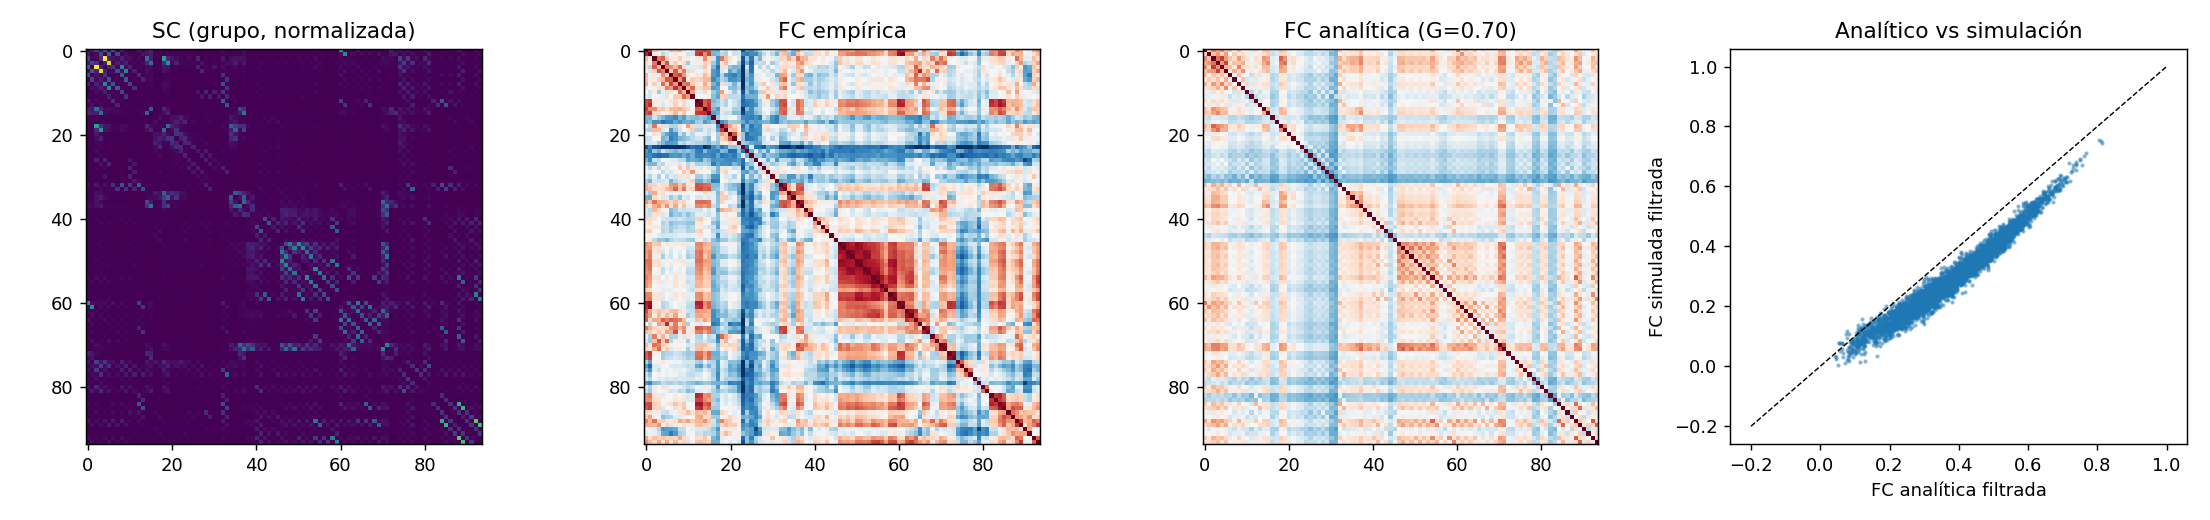

In [6]:
display(Image(str(ROOT / 'figures' / 'fase1_matrices.png')))

## Lectura de resultados

**Lo que se reproduce (validación):**
1. El mejor ajuste ocurre **en el borde de la bifurcación** ($a\to 0^-$), como reporta la literatura.
2. En $G\approx 1$ coinciden tres criterios independientes: máximo de $r(\mathrm{FC})\approx 0.52$, FC media simulada ≈ empírica (0.40 vs 0.37) y **pico de metaestabilidad** (0.20, dentro de ~1.5 DE del valor empírico 0.18).
3. La FC analítica filtrada coincide con la simulada filtrada ($r = 0.92$–$0.98$); cerca de $a=0$ la teoría lineal sobreestima ligeramente el nivel de correlación (efecto de saturación visto en la Fase 0).

**Lo que no se reproduce todavía:**
- **FCD**: la distancia KS es mínima en $G\approx 3.5$, donde la FC media ya es 0.8 (demasiado sincronizada). Con $a$ homogéneo el modelo no puede tener a la vez el nivel de FC y la variabilidad temporal correctos.
- **Anticorrelaciones**: la FC empírica tiene franjas negativas (p. ej. regiones ~22–27) que un acoplamiento difusivo con pesos positivos no genera.
- $r\approx 0.5$ es típico de modelos con SC cruda y parámetros homogéneos.

**Siguientes pasos naturales:**
- $a_j$ heterogéneo por región (Deco et al. 2017 lo ajustan con un gradiente; aquí podemos hacerlo con el gradiente analítico de $\Sigma_H$).
- *Conectividad efectiva*: ajustar los pesos $C_{jk}$ partiendo de la SC (r típicamente sube a 0.7–0.9).
- Estudiar $\delta$ por sujeto y su relación con *critical slowing down* medido directamente en el BOLD.